# Generate test signals

Build your own stimulus, look at it, and write it out as Q-format files for the VHDL testbenches and the board.

1. **Parameters** - sample rate, length, word format, output folder.
2. **Define signals** - combine the building blocks from `gen_signals.py` (edit freely).
3. **Look at them** - time domain and spectrum.
4. **Quantize and write** - `.txt` (signed decimal, for `textio`) and `.hex` (two's complement, for BRAM init).

Run top to bottom. Only sections 1 and 2 normally need editing.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "../models")
from gen_signals import (sine, add, scale, dc, gaussian_noise, uniform_noise,
                         step, impulse, square, chirp, to_codes, generate, plot)

## 1. Parameters

`INT_BITS` counts the sign bit, so Q2.15 covers -2.0 .. +1.99997 in steps of 2^-15.
Use a different `OUT_DIR` than `../stimulus` (the standard set made by `python3 gen_signals.py`) so you don't overwrite it.

In [2]:
FS        = 1000.0   # sample rate in Hz
N         = 2048     # samples per signal
INT_BITS  = 2        # integer bits, including sign
FRAC_BITS = 15       # fractional bits
SEED      = 1234     # noise seed - same seed gives the same noise every run

OUT_DIR   = "../stimulus_custom"
WRITE     = True     # False = just look, don't write files

## 2. Define signals

Each entry is `name: list of floats`. Amplitudes are real numbers (1.0 = full "one" in Qm.f), so keep the **peak** below `2**(INT_BITS-1)`, otherwise samples saturate (reported in section 4).

Building blocks: `sine(freq, amp)`, `square(freq, amp)`, `chirp(f0, f1, amp)`, `step(amp, start)`, `impulse(amp, at)`, `dc(level)`, `gaussian_noise(sigma)`, `uniform_noise(amp)`, combined with `add(...)` and `scale(x, gain)`. Pass `n=N, fs=FS` so they follow the parameters above.

In [3]:
signals = {
    # same shapes as the standard set, now following FS / N above
    "sine_10hz":         sine(10, 1.0, n=N, fs=FS),
    "compound_10_100hz": add(sine(10, 0.8, n=N, fs=FS), sine(100, 0.5, n=N, fs=FS)),
    "noisy_sine_10hz":   add(sine(10, 0.8, n=N, fs=FS), gaussian_noise(0.2, n=N, seed=SEED)),

    # examples of building your own
    "three_tones":       add(sine(5, 0.5, n=N, fs=FS), sine(50, 0.4, n=N, fs=FS), sine(200, 0.3, n=N, fs=FS)),
    "sine_plus_dc":      add(dc(0.5, n=N), sine(20, 0.6, n=N, fs=FS)),
    "noisy_square_5hz":  add(square(5, 0.6, n=N, fs=FS), uniform_noise(0.15, n=N, seed=SEED)),
}

## 3. Look at them

Time domain first. Then the magnitude spectrum, which needs a little explanation (what it shows, and why the plot uses a window) before the plot for your signals.


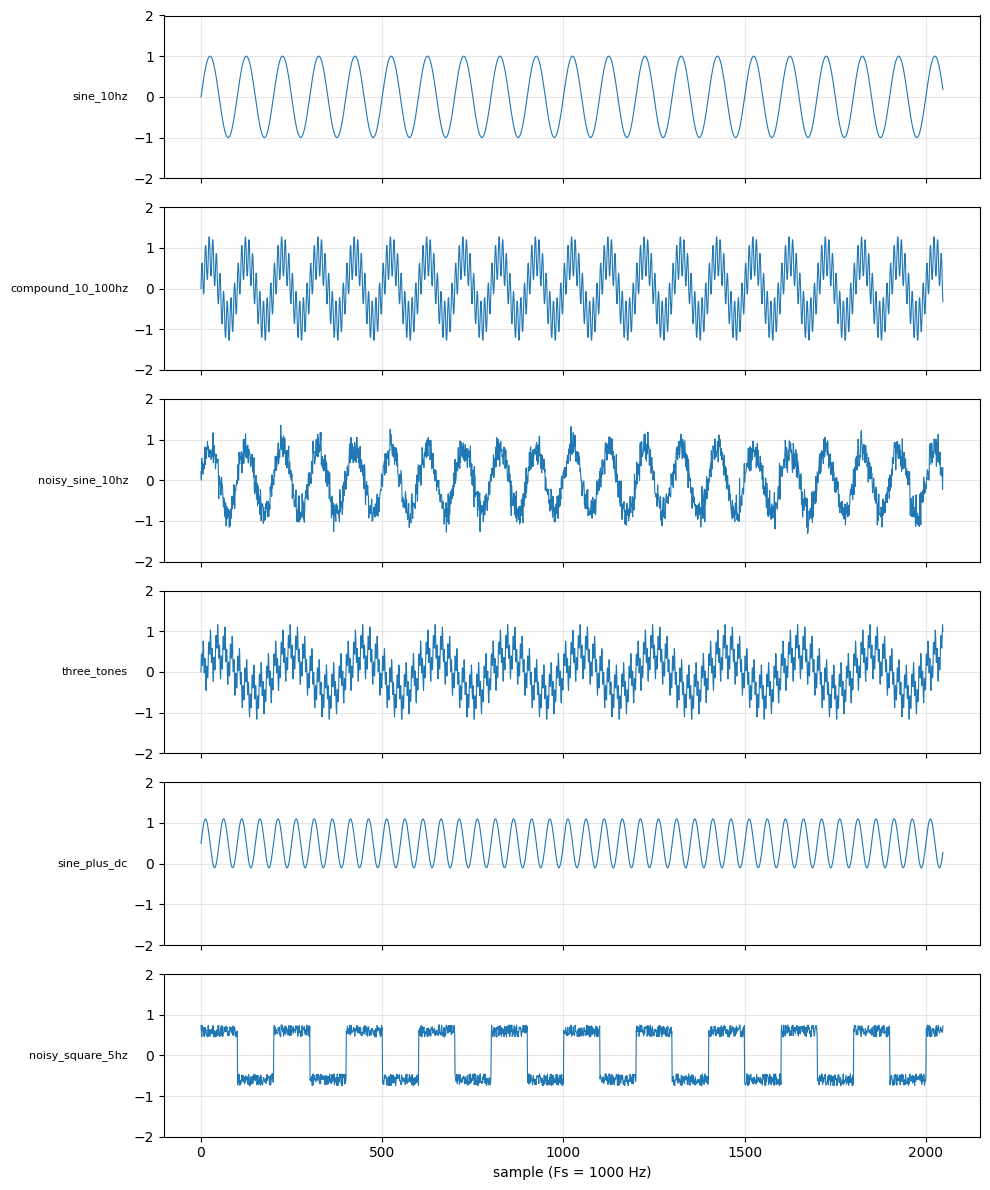

In [4]:
# Quantize in memory only (files are written in section 4), so the plots show exactly what the hardware will see.
codes = {k: to_codes(v, INT_BITS, FRAC_BITS) for k, v in signals.items()}

fig = plot(codes, fs=FS, frac_bits=FRAC_BITS, int_bits=INT_BITS)
plt.show()

### What is a tone?

A **tone** is a sinusoid at one single frequency, with constant amplitude and phase: `A · sin(2π f t + φ)`. `sine(10, 0.8)` in this notebook is a 0.8-amplitude, 10 Hz tone.

The word comes from sound. A tuning fork or a whistle produces a pure sine wave, and the ear hears that as a single steady pitch, a *tone*. In signal processing the word kept that meaning: "tone" is the thing that has exactly one frequency. You will also see it in `two-tone test` (feed two sinusoids at once to see how a system mixes them), `pilot tone`, `DTMF tones`.

Tone versus noise is the useful contrast. A tone puts all of its energy at one frequency, so it is a **spike** in the spectrum. Noise spreads its energy over all frequencies, so it is a flat **floor**. Everything else (a square wave, speech) is some mixture of tones, which is why the spectrum is such a useful picture.

### Reading a magnitude spectrum

The time-domain plot answers *when*: what the value is at each instant. The spectrum answers *how much of each frequency* the record contains.

**The idea.** Any record of `N` samples can be written as a sum of sinusoids at the frequencies `0, Fs/N, 2·Fs/N, …, Fs/2`. For each of those frequencies the FFT gives two numbers: how large that sinusoid is (amplitude) and where in its cycle it starts (phase). The **magnitude** spectrum keeps the first and throws the second away. That is why a pure tone is one spike, and why shifting a signal in time does not change its magnitude spectrum.

**The axes**

- **x, frequency.** Point `k` sits at `k · Fs/N`. With `Fs = 1000` and `N = 2048` the points ("bins") are 0.488 Hz apart, from 0 up to Nyquist (`Fs/2 = 500 Hz`). A real signal has mirror-image negative frequencies that carry no extra information, so `np.fft.rfft` returns only the positive half: `N/2 + 1 = 1025` bins.
- **y, level in dB.** What the numbers mean is explained in the cell below.

**The scale factor** `/ (window.sum() / 2)` makes a sine of amplitude `A` read `A` at its peak. A real sine of amplitude `A` is really two complex exponentials of amplitude `A/2` at `+f` and `-f`, and `rfft` keeps only the `+f` half, hence the `2`. The `window.sum()` undoes the gain of the window (next section). Two consequences: a **DC level reads twice its value** (it has no mirror partner, so nothing was split off), and the height of a peak is only exact if the tone sits exactly on a bin (see below).

**What to look for:** tones are spikes, noise is a flat floor, a square wave is a spike at its frequency plus smaller spikes at 3x, 5x, 7x...

### What the numbers on the y axis mean

Each point on the spectrum answers one question: *how big a sinusoid at this frequency would I have to add up to reproduce this part of the signal?* The y value is that sinusoid's **amplitude**, measured against 1.0 and expressed in decibels:

`level_dB = 20 · log10(amplitude / 1.0)`

- **0 dB** is amplitude 1.0 (a sine that swings between -1 and +1).
- **Negative numbers** are smaller than 1.0, and every 20 dB is a factor of 10: `-20 dB = 0.1`, `-40 dB = 0.01`, `-60 dB = 0.001`. Every 6 dB is a factor of 2.
- **Why log at all?** The interesting range is huge. A tone at 1.0 and a noise floor at 0.005 differ by 200x; on a linear axis the floor would be a line on the axis. In dB both are readable on the same plot.
- **Why 20 and not 10?** Decibels were defined for *power*, `10·log10(power)`. Power goes as amplitude squared, and `log(a²) = 2·log(a)`, which turns the 10 into a 20 when you start from amplitude.

The table puts numbers on it, including what it means in the integer codes the VHDL will see (Q2.15, one LSB = 2^-15):

In [5]:
rows = [("1.0", 1.0), ("0.5", 0.5), ("0.1", 0.1), ("0.01", 0.01), ("0.001", 0.001), ("1 LSB = 2^-15", 2.0 ** -15)]
print(f"{'amplitude':>14} {'level':>10} {'size in Q2.15 codes':>22}")
for label, a in rows:
    print(f"{label:>14} {20 * np.log10(a):>7.1f} dB {a * 2 ** FRAC_BITS:>22,.1f}")

     amplitude      level    size in Q2.15 codes
           1.0     0.0 dB               32,768.0
           0.5    -6.0 dB               16,384.0
           0.1   -20.0 dB                3,276.8
          0.01   -40.0 dB                  327.7
         0.001   -60.0 dB                   32.8
 1 LSB = 2^-15   -90.3 dB                    1.0


Three things to keep in mind when reading a level:

- **0 dB here means amplitude 1.0, not hardware full scale.** The plot title says "dBFS-ish" because Q2.15 full scale is actually 2.0, so true dBFS would read 6 dB lower. The spectrum is only for looking at the signal and does not affect the files.
- **One LSB is about -90 dB.** A feature around -90 dB is the size of the quantization step. Anything much lower than that cannot be a real property of a Q2.15 signal; it is rounding, or numerical noise from the calculation. That is why the all-signals plot below stops at -100 dB.
- **For noise, the number is a per-bin level, not the noise amplitude.** Gaussian noise with sigma = 0.2 has an rms of 0.2 (-14 dB) in the time domain, but its energy is shared by 1025 bins, so each bin shows only about -42 dB. The floor therefore also depends on `N` (see "what each plot should show" below).

### What is a bin?

The FFT does not measure every possible frequency. It measures `N/2 + 1` specific ones, evenly spaced like the marks on a ruler. Each mark is a **bin**. Bin `k` answers one question: *how much of the frequency `k · Fs/N` is in this record?* Think of the FFT as a row of detectors, each tuned to its own frequency.

**Why the marks are `Fs/N` apart.** The record lasts `T = N/Fs` seconds (2.048 s here). The only sinusoids that fit a *whole* number of cycles into the record are the ones at `1/T, 2/T, 3/T, …` Hz, and those are exactly the frequencies the FFT tests for. So the spacing is `1/T = Fs/N = 0.488 Hz`.

What follows from that:

- **Resolution comes from the record length, not from the sample rate.** To tell two tones apart that are 1 Hz apart you need a record of at least about a second (a bit more with a window). Sampling faster adds nothing; recording longer helps.
- **The range comes from the sample rate.** The last bin is at `Fs/2` (see aliasing below).
- **A tone that is not on a mark is seen by the bins on both sides of it, and a little by all the others.** The 10 Hz tone is 20.48 cycles long, which is between mark 20 and mark 21. That is the root of everything in the window section.

In [6]:
T = N / FS
print(f"record length T = N/Fs = {T:.3f} s  ->  bin spacing 1/T = Fs/N = {FS / N:.4f} Hz   ({N // 2 + 1} bins up to {FS / 2:.0f} Hz)\n")

tone = 10.0
print(f"a {tone:g} Hz tone completes {tone * T:.2f} cycles in the record\n")
print(f"{'bin k':>6} {'bin freq (Hz)':>14} {'cycles of this bin in record':>30} {'tone is this many bins away':>30}")
for k in range(19, 23):
    fk = k * FS / N
    print(f"{k:>6} {fk:>14.3f} {k:>30d} {(tone - fk) / (FS / N):>+30.2f}")

record length T = N/Fs = 2.048 s  ->  bin spacing 1/T = Fs/N = 0.4883 Hz   (1025 bins up to 500 Hz)

a 10 Hz tone completes 20.48 cycles in the record

 bin k  bin freq (Hz)   cycles of this bin in record    tone is this many bins away
    19          9.277                             19                          +1.48
    20          9.766                             20                          +0.48
    21         10.254                             21                          -0.52
    22         10.742                             22                          -1.52


### Why a window?

The FFT quietly assumes that the `N` samples you give it are **one period of a signal that repeats forever**. If the record holds a whole number of cycles, the copies join smoothly. If not, the end of the record does not meet its own beginning, and the repeated signal has a **jump** at every seam.

Here `10 Hz × 2.048 s = 20.48` cycles, so there *is* a jump. A jump is a sharp edge, and a sharp edge contains energy at all frequencies. So one clean 10 Hz tone shows up as the spike *plus a skirt of energy across every other bin*. This is **spectral leakage**, and it would bury the small things (the noise floor, a weak second tone) that you actually want to see.

A **window** fixes it by multiplying the record by a smooth bell that goes to zero at both ends, so there is nothing left to jump. The plot uses the Hann window, `w[n] = 0.5 · (1 − cos(2πn / (N−1)))`. The next cell shows both effects: the seams in the time domain (top) and what they do to the spectrum (bottom).

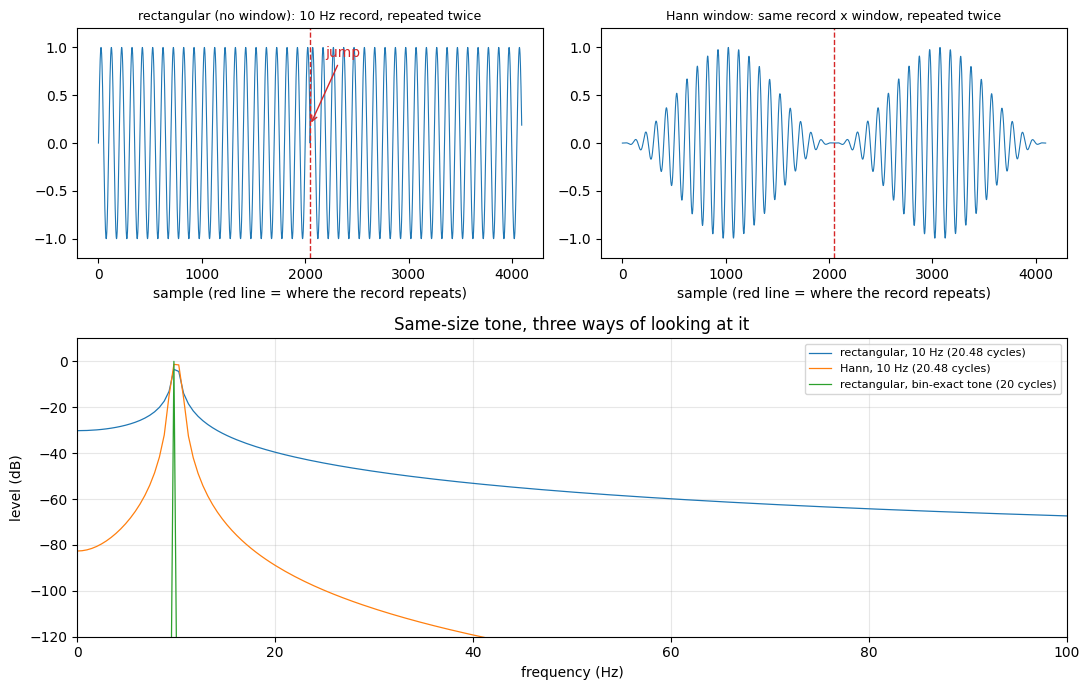

                                           peak reads   level >5 Hz away
rectangular, 10 Hz (20.48 cycles)           0.670 (-3.5 dB)     -28.3 dB
Hann, 10 Hz (20.48 cycles)                  0.860 (-1.3 dB)     -71.3 dB
rectangular, bin-exact tone (20 cycles)     1.000 (+0.0 dB)    -240.0 dB


In [7]:
n = np.arange(N)
t = n / FS
f_odd = 10.0                   # 20.48 cycles in the record: does not close on itself
f_exact = 20 * FS / N          # exactly 20 cycles: sits exactly on bin 20
hann = np.hanning(N)
rect = np.ones(N)

x_odd = np.sin(2 * np.pi * f_odd * t)
x_exact = np.sin(2 * np.pi * f_exact * t)

def mag(x, w):
    return np.abs(np.fft.rfft(x * w)) / (w.sum() / 2)

fq = np.fft.rfftfreq(N, d=1 / FS)
db = lambda a: 20 * np.log10(a + 1e-12)

fig = plt.figure(figsize=(11, 7))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.3])

for col, (title, y) in enumerate([("rectangular (no window): 10 Hz record, repeated twice", x_odd),
                                  ("Hann window: same record x window, repeated twice", x_odd * hann)]):
    ax = fig.add_subplot(gs[0, col])
    ax.plot(np.arange(2 * N), np.tile(y, 2), lw=0.8)
    ax.axvline(N, color='tab:red', ls='--', lw=1)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel('sample (red line = where the record repeats)')
    ax.set_ylim(-1.2, 1.2)
    if col == 0:
        ax.annotate('jump', xy=(N, x_odd[-1]), xytext=(N + 150, 0.9), color='tab:red',
                    arrowprops=dict(arrowstyle='->', color='tab:red'))

ax = fig.add_subplot(gs[1, :])
curves = [("rectangular, 10 Hz (20.48 cycles)", mag(x_odd, rect), 'tab:blue'),
          ("Hann, 10 Hz (20.48 cycles)", mag(x_odd, hann), 'tab:orange'),
          ("rectangular, bin-exact tone (20 cycles)", mag(x_exact, rect), 'tab:green')]
for label, s, color in curves:
    ax.plot(fq, db(s), lw=0.9, label=label, color=color)
ax.set_xlim(0, 100)
ax.set_ylim(-120, 10)
ax.set_xlabel('frequency (Hz)')
ax.set_ylabel('level (dB)')
ax.grid(alpha=0.3)
ax.legend(loc='upper right', fontsize=8)
ax.set_title('Same-size tone, three ways of looking at it')
fig.tight_layout()
plt.show()

print(f"{'':42} {'peak reads':>10} {'level >5 Hz away':>18}")
for label, s, _ in curves:
    k = s.argmax()
    away = db(s[np.abs(fq - fq[k]) > 5]).max()
    print(f"{label:42} {s[k]:>6.3f} ({db(s[k]):+.1f} dB) {away:>9.1f} dB")

What the demo shows (the amplitude of the test tone is exactly 1.0 in all three):

| | peak reads | strongest leakage far from the peak | main-lobe width |
|---|---|---|---|
| rectangular, 20.48 cycles | 0.67 (-3.5 dB) | about -28 dB, and the skirt decays slowly | narrow (about 2 bins) |
| **Hann**, 20.48 cycles | 0.86 (-1.3 dB) | about -71 dB, and it dies off quickly | wider (about 4 bins) |
| rectangular, 20 cycles (bin-exact) | 1.00 (0 dB) | nothing: the record closes on itself | narrow |

- **Leakage is the point of the window.** Without it, a unit tone leaves a skirt around -28 dB across the plot, and the noise floor of `noisy_sine_10hz` (about -42 dB) would be drowned by it. With Hann the skirt is 40 dB lower, so the floor stays visible.
- **The price is resolution.** A window smears each tone over more bins (Hann: about twice as wide). Two tones closer than a few bins merge. The test signals have tones far apart, so Hann costs nothing here.
- **The peak of an off-bin tone reads low.** The tone sits between two bins and neither shows its full height (*scalloping*: up to -3.9 dB for rectangular, up to -1.4 dB for Hann). So the 10 Hz tone of amplitude 0.8 in `compound_10_100hz` will read about 0.69, not 0.80. The *signal* is exactly right; only the plot is off.
- **If you need peak heights to be exact**, make the tone fit a whole number of cycles: choose the frequency as `k · Fs/N`, or choose `N` as a multiple of the period (`N = 2000` gives exactly 20 cycles of 10 Hz at 1 kHz). Then even the rectangular window is clean, as the green curve shows.
- **The window is only applied for plotting.** The `.txt` and `.hex` files hold the raw, unwindowed samples.

### Looking through one bin: what a window really changes

Take one bin as a detector tuned to one frequency, say bin 20 (9.77 Hz). Now slide a unit tone across the frequency axis and ask: *how strongly does this detector respond?* That curve is the **response of the bin**, and it is the cleanest way to see what a window does. (The window does not change the signal. It changes the shape of every detector.)

- **No window (rectangular):** a peak one bin wide on each side, followed by ripples (*sidelobes*) that die away slowly. The first ripple is only about -13 dB below the peak. A strong tone far away still pushes a little into this bin through those ripples: **that is leakage**.
- **Hann window:** the peak is about twice as wide (it reaches out two bins on each side), but the ripples start at about -31 dB and fall off quickly. Far-away tones barely register.
- **Halfway between two marks** (0.5 bin from the centre) the detector sees the tone at reduced height: about -4 dB for rectangular, about -1.4 dB for Hann. This is the **scalloping** loss from the previous section.

So the window is a trade: a wider peak (less resolution, as two close tones merge) for much lower far-away leakage and a flatter response between bins. For finding tones and a noise floor on a plot, that trade is almost always worth it.

rectangular (no window)  at 0.5 bin off-centre: -3.8 dB   highest sidelobe: -13.0 dB
Hann                     at 0.5 bin off-centre: -1.4 dB   highest sidelobe: -31.5 dB


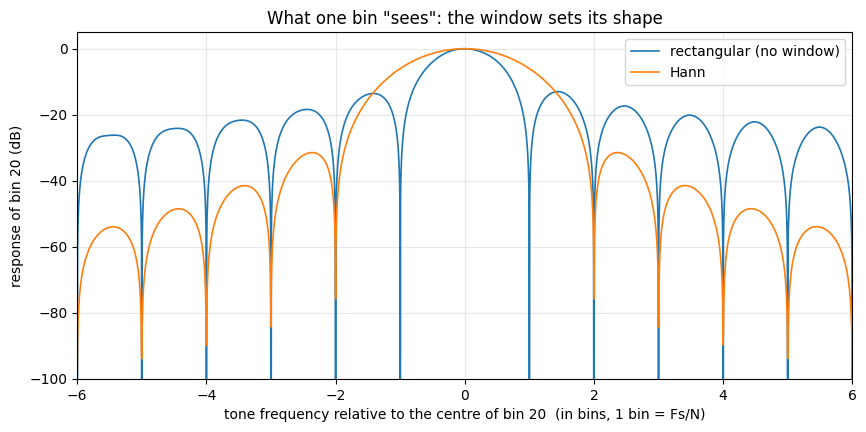

In [8]:
k0 = 20
nn = np.arange(N)
kern = np.exp(-2j * np.pi * k0 * nn / N)            # the "detector" tuned to bin 20
d = np.linspace(-6, 6, 2401)                        # tone position relative to bin 20, in bins
tones = np.sin(2 * np.pi * (k0 + d)[:, None] * nn / N)

fig, ax = plt.subplots(figsize=(10, 4.5))
for label, w in (("rectangular (no window)", np.ones(N)), ("Hann", np.hanning(N))):
    resp = np.abs((tones * w * kern).sum(axis=1)) / (w.sum() / 2)
    ax.plot(d, 20 * np.log10(resp + 1e-12), label=label, lw=1.2)
    half = 20 * np.log10(resp[np.argmin(np.abs(d - 0.5))])
    side0 = 1.0 if 'rect' in label else 2.0
    side = 20 * np.log10(resp[np.abs(d) > side0 + 0.05].max())
    print(f"{label:24} at 0.5 bin off-centre: {half:+.1f} dB   highest sidelobe: {side:.1f} dB")
ax.set_xlim(-6, 6)
ax.set_ylim(-100, 5)
ax.set_xlabel('tone frequency relative to the centre of bin 20  (in bins, 1 bin = Fs/N)')
ax.set_ylabel('response of bin 20 (dB)')
ax.set_title('What one bin "sees": the window sets its shape')
ax.grid(alpha=0.3)
ax.legend()
plt.show()

Two details in the plot:

- **Both curves touch zero at whole-bin distances** (rectangular at ±1, ±2, ±3 …; Hann at ±2, ±3 …). A tone with a whole number of cycles that sits exactly on another bin is invisible to this one. That is why a bin-exact tone gives a clean result: a single spike with no window, or, with Hann, three bins (the centre at 0 dB and its two neighbours at -6 dB) and nothing else.
- **Between the notches are the ripples, and the ripples are the leakage.** An off-bin tone lands on a ripple. The rectangular ripples stay high (-13 dB and then slowly lower, still around -25 dB at 6 bins away). The Hann ripples are 20 to 40 dB lower and keep falling, which is what keeps the noise floor visible.


### The spectrum of every signal (Hann window)

Same calculation as above, applied to each of your signals.

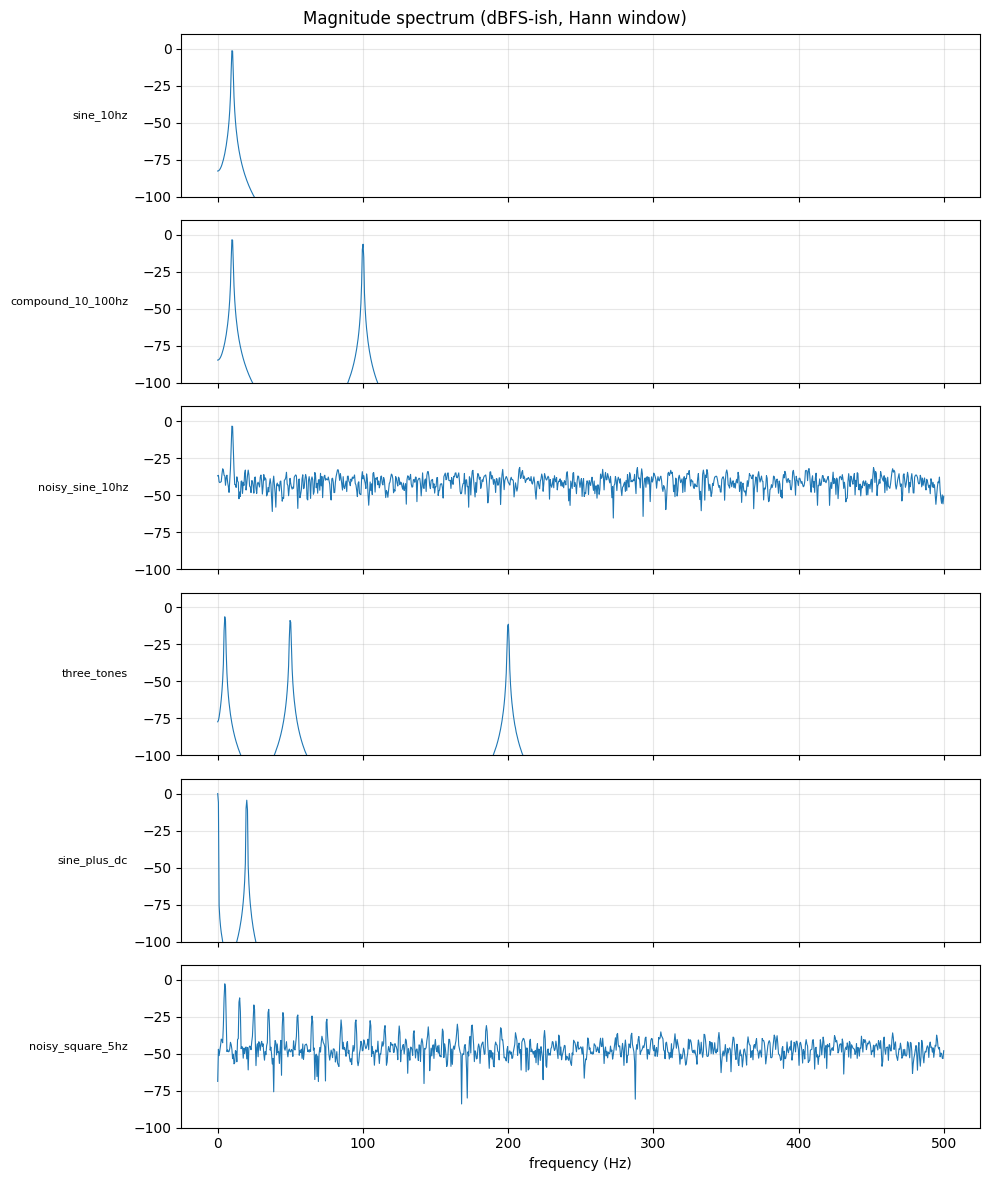

In [9]:
fig, axes = plt.subplots(len(codes), 1, figsize=(10, 2 * len(codes)), sharex=True, squeeze=False)
freqs = np.fft.rfftfreq(N, d=1 / FS)
window = np.hanning(N)
for ax, (name, c) in zip(axes[:, 0], codes.items()):
    x = np.array(c) / 2**FRAC_BITS
    spec = np.abs(np.fft.rfft(x * window)) / (window.sum() / 2)
    ax.plot(freqs, 20 * np.log10(spec + 1e-12), lw=0.8)
    ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=8)
    ax.set_ylim(-100, 10)
    ax.grid(alpha=0.3)
axes[-1, 0].set_xlabel("frequency (Hz)")
fig.suptitle("Magnitude spectrum (dBFS-ish, Hann window)")
fig.tight_layout()
plt.show()

What each plot should show:

- **Tones:** a spike at each tone's frequency, with height `≈ amplitude` (a little low if the tone is off-bin, as explained above).
- **`noisy_sine_10hz`, `noisy_square_5hz`:** a flat floor. Its level depends on `N`, not just on the noise amplitude: every doubling of `N` halves the bin width, so each bin catches half the noise power and the floor drops by 3 dB, while tones keep their height. The floor of Gaussian noise with `sigma = 0.2` sits around -42 dB at `N = 2048` and -45 dB at `N = 4096`.
- **`sine_plus_dc`:** a spike at 0 Hz that reads twice the DC level (0.5 reads 1.0), for the reason given at the top.
- **`noisy_square_5hz`:** spikes at 5, 15, 25 Hz... (odd harmonics), falling off as 1/k.
- **Anything below about -100 dB** is cut off at the bottom of the plot (`set_ylim(-100, 10)`).

### Why does a square wave have harmonics?

Look at `noisy_square_5hz` above. It is a 5 Hz square wave, yet the spectrum has spikes at 5, 15, 25, 35 Hz... Those extra spikes are **harmonics**: sinusoids at integer multiples of the repetition frequency (`f0, 2·f0, 3·f0, …`). They are not an artefact and not the noise. The noise only raises the floor underneath them.

**Why they must exist.** A sinusoid is smooth and round. A square wave has flat tops and vertical edges. One sinusoid at `f0` can follow the general rise and fall, but it overshoots the flat part and cannot make the corner. Adding a smaller sinusoid at `3·f0` straightens the top and steepens the edge; then one at `5·f0` fixes what is left, and so on. The sharper the edge, the more of these you need, and that is exactly what the spectrum shows. (Fourier's result: any repeating shape is a sum of sinusoids at multiples of its repetition frequency.)

**Why only the odd ones.** The second half of a square period is the first half upside down: `x(t + T/2) = -x(t)`. A sinusoid at harmonic `k` shifted by half a period gets multiplied by `(-1)^k`. For even `k` it comes back *unchanged*, so no combination of even harmonics can produce a signal that flips sign. Odd harmonics flip sign, so only they appear.

**Why they get smaller as `1/k`.** Each odd harmonic has amplitude `4A / (π·k)`. For `A = 0.6` that is 0.764 (-2.3 dB) at `f0`, 0.255 (-11.9 dB) at `3·f0`, 0.153 (-16.3 dB) at `5·f0`... The jump in the edge is what makes the series fall only as `1/k`, which is slow: a square wave needs many harmonics, and that is why its edges ring if you filter it. The next cell builds a square wave back up from its harmonics and checks the amplitudes against the formula.

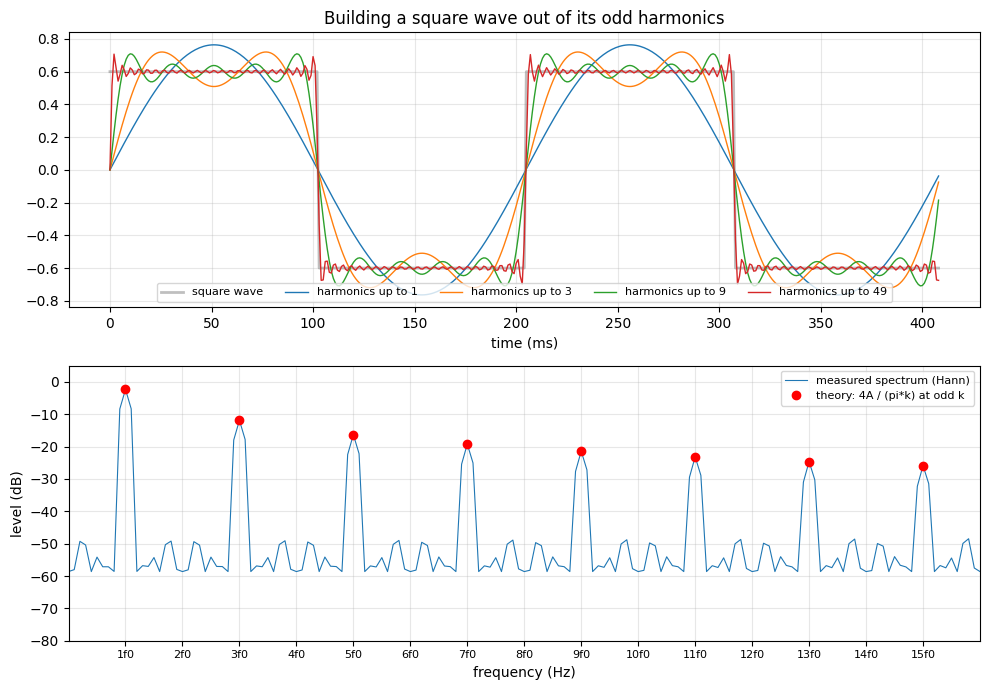

  k   theory  measured     level
  1   0.7639    0.7639   -2.3 dB
  2   0.0000    0.0013  -58.0 dB
  3   0.2546    0.2546  -11.9 dB
  4   0.0000    0.0013  -57.9 dB
  5   0.1528    0.1528  -16.3 dB
  6   0.0000    0.0013  -57.9 dB
  7   0.1091    0.1091  -19.2 dB
  8   0.0000    0.0013  -57.8 dB
  9   0.0849    0.0849  -21.4 dB
 10   0.0000    0.0013  -57.7 dB
 11   0.0694    0.0694  -23.2 dB


In [10]:
f0 = 10 * FS / N                 # exactly 10 cycles per record, so every harmonic sits on a bin
A = 0.6
sq = np.array(square(f0, A, n=N, fs=FS))
t = np.arange(N) / FS

def partial_sum(max_harmonic):
    y = np.zeros(N)
    for k in range(1, max_harmonic + 1, 2):                       # odd harmonics only
        y += 4 * A / (np.pi * k) * np.sin(2 * np.pi * k * f0 * t)
    return y

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7))

two_periods = int(2 * FS / f0)
ax1.plot(t[:two_periods] * 1000, sq[:two_periods], color='gray', lw=2, alpha=0.5, label='square wave')
for h in (1, 3, 9, 49):
    ax1.plot(t[:two_periods] * 1000, partial_sum(h)[:two_periods], lw=1, label=f'harmonics up to {h}')
ax1.set_xlabel('time (ms)')
ax1.set_title('Building a square wave out of its odd harmonics')
ax1.legend(fontsize=8, ncol=5, loc='lower center')
ax1.grid(alpha=0.3)

w = np.hanning(N)
spec = np.abs(np.fft.rfft(sq * w)) / (w.sum() / 2)
fq = np.fft.rfftfreq(N, d=1 / FS)
ax2.plot(fq, 20 * np.log10(spec + 1e-12), lw=0.8, label='measured spectrum (Hann)')
hs = np.arange(1, 16, 2)
ax2.plot(hs * f0, 20 * np.log10(4 * A / (np.pi * hs)), 'ro', label='theory: 4A / (pi*k) at odd k')
ax2.set_xlim(0, 16 * f0)
ax2.set_ylim(-80, 5)
ax2.set_xlabel('frequency (Hz)')
ax2.set_ylabel('level (dB)')
ax2.set_xticks([k * f0 for k in range(1, 16)], [f'{k}f0' for k in range(1, 16)], fontsize=8)
ax2.grid(alpha=0.3)
ax2.legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"{'k':>3} {'theory':>8} {'measured':>9} {'level':>9}")
for k in range(1, 12):
    meas = spec[10 * k - 1:10 * k + 2].max()
    th = 4 * A / (np.pi * k) if k % 2 else 0.0
    print(f"{k:>3} {th:>8.4f} {meas:>9.4f} {20 * np.log10(meas + 1e-12):>6.1f} dB")

Reading the result:

- The top plot shows the construction: harmonic 1 alone is a sine, adding 3 flattens the top, and by 49 the edges are nearly vertical. The small overshoot next to the edge never goes away however many harmonics you add (the *Gibbs* effect, about 9% of the jump).
- In the bottom plot the red dots are the formula and the blue curve is the measurement. They agree on every odd harmonic.
- The **even harmonics are not exactly zero** in the measurement (about -58 dB, versus -2 to -20 dB for the odd ones). In theory they cancel completely; here the sampled edges land between samples, which breaks the exact half-period symmetry by a tiny amount.
- **The noise is not a harmonic.** In `noisy_square_5hz` the uniform noise just lifts the floor to about -49 dB. The harmonics stay visible as long as they are above that floor.
- **Aliasing caveat:** a true square wave has harmonics out to infinity, but sampling at 1 kHz can only represent frequencies up to 500 Hz. Harmonics beyond that fold back into the plot and add onto bins that already have a harmonic, so the highest ones read slightly off.

### Aliasing and the Nyquist limit (`Fs/2`)

Sampling looks at the signal only at instants `1/Fs` apart. To represent a sinusoid you need at least two samples per cycle, so the highest frequency a sampled signal can hold is **`Fs/2`, the Nyquist frequency**. Here that is `1000 / 2 = 500 Hz`, the right-hand edge of every spectrum plot.

Above that, frequencies are no longer distinguishable. A tone at `f` and a tone at `Fs - f` produce the same samples, and so does `Fs + f`. The tone does not disappear: it **folds back** into the band `0 … Fs/2`:

`f_alias = | f − Fs · round(f / Fs) |`

At `Fs = 1 kHz`: 600 Hz shows up at 400 Hz, 900 Hz at 100 Hz, 1100 Hz at 100 Hz. Picture the frequency axis folded like an accordion at `Fs/2`, `Fs`, `3Fs/2`, …

The cell below shows it. Top: a 100 Hz tone and a 1100 Hz tone are different waves, but at 1 kHz sampling every sample lands on the same value. Bottom: a generated `sine(600)` really has its spectrum peak at 400 Hz.

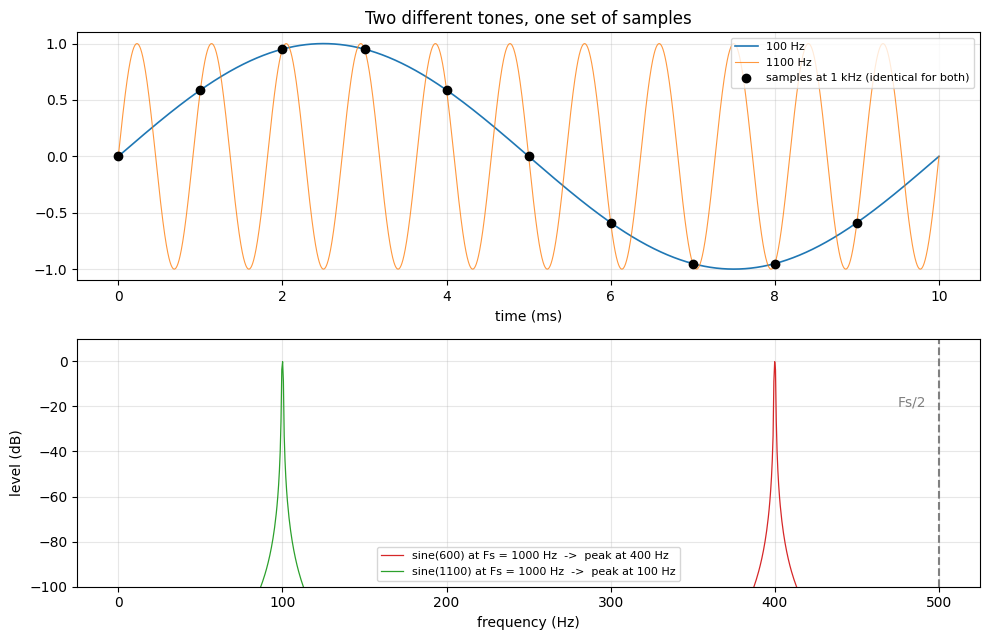

 input (Hz) ->  appears at (Hz)
        100 ->              100
        400 ->              400
        450 ->              450
        600 ->              400
        900 ->              100
       1100 ->              100
       1900 ->              100

exactly at Fs/2, the samples depend on the phase and can vanish entirely:
  phase   0 deg:  [ 0.  0. -0.  0. -0.  0.]
  phase  45 deg:  [ 0.707 -0.707  0.707 -0.707  0.707 -0.707]
  phase  90 deg:  [ 1. -1.  1. -1.  1. -1.]


In [11]:
tt = np.linspace(0, 0.010, 4000)                # "continuous" time, first 10 ms
ts = np.arange(10) / FS                         # the sample instants at Fs = 1 kHz

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.5))
ax1.plot(tt * 1000, np.sin(2 * np.pi * 100 * tt), label='100 Hz', lw=1.2)
ax1.plot(tt * 1000, np.sin(2 * np.pi * 1100 * tt), label='1100 Hz', lw=0.8, alpha=0.8)
ax1.plot(ts * 1000, np.sin(2 * np.pi * 100 * ts), 'ko', label='samples at 1 kHz (identical for both)')
ax1.set_xlabel('time (ms)')
ax1.set_title('Two different tones, one set of samples')
ax1.legend(fontsize=8, loc='upper right')
ax1.grid(alpha=0.3)

w = np.hanning(N)
fq = np.fft.rfftfreq(N, d=1 / FS)
for f_in, color in ((600, 'tab:red'), (1100, 'tab:green')):
    x = np.array(sine(f_in, 1.0, n=N, fs=FS))
    s = np.abs(np.fft.rfft(x * w)) / (w.sum() / 2)
    ax2.plot(fq, 20 * np.log10(s + 1e-12), lw=0.9, color=color, label=f'sine({f_in}) at Fs = {FS:g} Hz  ->  peak at {fq[s.argmax()]:.0f} Hz')
ax2.axvline(FS / 2, color='gray', ls='--')
ax2.text(FS / 2 - 8, -20, 'Fs/2', ha='right', color='gray')
ax2.set_ylim(-100, 10)
ax2.set_xlabel('frequency (Hz)')
ax2.set_ylabel('level (dB)')
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)
fig.tight_layout()
plt.show()

alias = lambda f: abs(f - FS * round(f / FS))
print(f"{'input (Hz)':>11} -> {'appears at (Hz)':>16}")
for f in (100, 400, 450, 600, 900, 1100, 1900):
    print(f"{f:>11} -> {alias(f):>16.0f}")

print("\nexactly at Fs/2, the samples depend on the phase and can vanish entirely:")
for phase in (0, np.pi / 4, np.pi / 2):
    print(f"  phase {np.degrees(phase):>3.0f} deg: ", np.round(np.sin(2 * np.pi * (FS / 2) * np.arange(6) / FS + phase), 3))

**Why you should care**

1. **It cannot be undone.** After sampling, an aliased component is indistinguishable from a genuine tone at the lower frequency. No digital processing can tell them apart, including the EMA filter in `dsp03`: to the filter, the folded tone *is* an in-band signal.
2. **In hardware, anything above `Fs/2` at the ADC input folds into your band.** Interference, noise and harmonics all do. That is why an ADC needs an analog **anti-alias low-pass filter** in front of it, with its corner safely below `Fs/2`. The same rule applies when you lower the sample rate later (decimation, for example in a lock-in filter chain): low-pass *first*, then drop samples.
3. **In these test signals it is silent.** `sine(600, ...)` at `Fs = 1 kHz` quietly becomes a 400 Hz tone and nothing warns you (this is in the README gotchas). The harmonics of a square wave above `Fs/2` fold onto existing harmonics, which is the caveat under the square-wave demo.
4. **The limit is strictly below `Fs/2`, not "up to".** At exactly `Fs/2` a sine has only two samples per cycle, and depending on its phase those samples can be `+A, -A, …` or all zero (the last lines above). Keep your tones comfortably under it. The chirp in the standard set tops out at 200 Hz with `Fs/2 = 500 Hz`.

**Summary of the two limits:** the sample rate sets the **maximum frequency**, `Fs/2`. The record length sets the **frequency resolution**, `Fs/N = 1/T`, which is the bin spacing.

## 4. Quantize and write

Writes `<name>.txt` and `<name>.hex` into `OUT_DIR` and reports min/max codes and any saturated samples.

In [12]:
if WRITE:
    generate(signals, out_dir=OUT_DIR, int_bits=INT_BITS, frac_bits=FRAC_BITS)
    print("written to", os.path.abspath(OUT_DIR))
else:
    print("WRITE is False - nothing written")

sine_10hz            2048 samples, min= -32768 max=  32768
compound_10_100hz    2048 samples, min= -41590 max=  41590
noisy_sine_10hz      2048 samples, min= -42845 max=  44422
three_tones          2048 samples, min= -38070 max=  38070
sine_plus_dc         2048 samples, min=  -3238 max=  36006
noisy_square_5hz     2048 samples, min= -24559 max=  24576
written to C:\Users\scholar\Documents\logic_playground\dsp02_test_signals\stimulus_custom
